In [1]:
from utils import add_project_root_to_sys_path
add_project_root_to_sys_path()

import polars as pl
from neuralnet.datasets import ParquetDataset
from neuralnet.plotting import hist_plot
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ATLAS)
from itertools import product

In [2]:
dataset = ParquetDataset(
    dataset_dir='/home/lucasbanunes/data/ringer-datasets/datasets/mc21_isabela_qt_2sigma_restriction'
)
dataset

ParquetDataset(dataset_dir=PosixPath('/home/lucasbanunes/data/ringer-datasets/datasets/mc21_isabela_qt_2sigma_restriction'))

In [3]:
electron_ringer_df = dataset.get_dataframe('electron_ringer')
kfold_df = dataset.get_dataframe('standard_binning_kfold')
development_df = (
    electron_ringer_df
    .join(kfold_df, on='id', how='inner')
    .filter(
        pl.col('label').is_not_null() &
        (pl.col('TrigEMClusterContainer.et') >= 15000) &
        (pl.col('TrigEMClusterContainer.eta').abs() < 2.5)
    )
)
development_df.collect_schema()

Schema([('id', UInt64),
        ('target', UInt8),
        ('DNNElectronTriggerContainer.tight', Boolean),
        ('DNNElectronTriggerContainer.medium', Boolean),
        ('DNNElectronTriggerContainer.loose', Boolean),
        ('ElectronContainer.calo_cluster.et', Float32),
        ('ElectronContainer.calo_cluster.eta', Float32),
        ('ElectronContainer.calo_cluster.phi', Float32),
        ('ElectronContainer.calo_cluster.etaBE2', Float32),
        ('ElectronContainer.calo_cluster.energy', Float32),
        ('ElectronContainer.et', Float32),
        ('ElectronContainer.eta', Float32),
        ('ElectronContainer.phi', Float32),
        ('ElectronContainer.reta', Float32),
        ('ElectronContainer.eratio', Float32),
        ('ElectronContainer.weta1', Float32),
        ('ElectronContainer.weta2', Float32),
        ('ElectronContainer.rhad', Float32),
        ('ElectronContainer.rhad1', Float32),
        ('ElectronContainer.rphi', Float32),
        ('ElectronContainer.f1', Float3

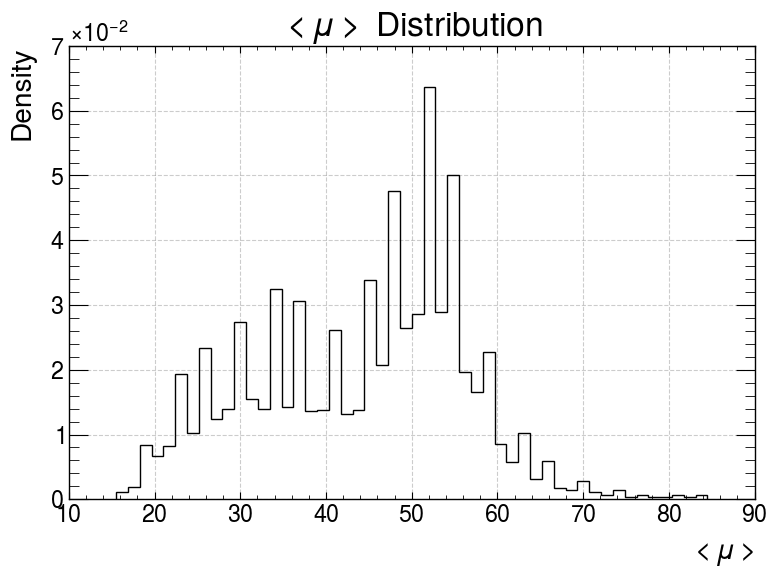

In [4]:
fig, ax = plt.subplots()
ax.grid(linestyle="--", alpha=0.2, color="k")
# ax.hist(avgmu, bins=50, histtype='step', color='black')
hist_plot(
    data=development_df,
    col='EventInfoContainer.avgmu',
    bins=50,
    density=True,
    ax=ax,
    color='k',
    label='$<\\mu>$'
    # alpha=0.5,
    # marker='s'
)
ax.set_title('$<\\mu>$ Distribution')
ax.set_ylabel('Density')
ax.set_xlabel('$<\\mu>$')
fig.tight_layout()

In [5]:
def count_committee_samples(
    data: pl.LazyFrame,
    et_bin=[15000, 20000, 30000, 40000, 50000, float('inf')],
    et_col='TrigEMClusterContainer.et',
    eta_bin=[0, 0.8, 1.37, 1.54, 2.37, 2.5],
    eta_col='TrigEMClusterContainer.eta',
    label_col='label'
) -> pl.DataFrame:
    counts = []
    bin_iterator = product(
        zip(et_bin[1:], et_bin[:-1]),
        zip(eta_bin[1:], eta_bin[:-1]),
    )
    for (et_bin_high, et_bin_low), (eta_bin_high, eta_bin_low) in bin_iterator:
        this_row = {
            'et_bin.low': et_bin_low,
            'et_bin.high': et_bin_high,
            'eta_bin.low': eta_bin_low,
            'eta_bin.high': eta_bin_high,
        }
        for label in range(2):
            if label:
                label_str = 'sig'
            else:
                label_str = 'bkg'
            this_row[f'{label_str}.count'] = (
                data
                .filter(
                    pl.col(et_col).is_between(et_bin_low, et_bin_high, closed='left') &
                    pl.col(eta_col).abs().is_between(eta_bin_low, eta_bin_high, closed='left') &
                    (pl.col(label_col) == label)
                )
                .select(pl.len())
                .collect()
                .item()
            )
        counts.append(this_row)
    return pl.DataFrame(counts)

In [6]:
committee_samples_count_df = count_committee_samples(development_df)
committee_samples_count_df

et_bin.low,et_bin.high,eta_bin.low,eta_bin.high,bkg.count,sig.count
i64,f64,f64,f64,i64,i64
15000,20000.0,0.0,0.8,209304,14575
15000,20000.0,0.8,1.37,163193,9200
15000,20000.0,1.37,1.54,42238,2987
15000,20000.0,1.54,2.37,211262,13146
15000,20000.0,2.37,2.5,17504,1249
…,…,…,…,…,…
50000,inf,0.0,0.8,14407,112033
50000,inf,0.8,1.37,11485,70720
50000,inf,1.37,1.54,3150,14211


In [22]:
import re

def add_midrules_to_tabular(latex_table: str) -> str:
    """
    Adds a \\midrule between all data rows in a LaTeX tabular string.
    Correctly ignores '\\\\' line breaks inside \\makecell{...} or other nested groups.
    """
    # Match the header midrule and the table bottomrule
    pattern = r'(\\midrule\b[^\n]*\n)(.*?)(\n\s*\\bottomrule)'
    match = re.search(pattern, latex_table, flags=re.DOTALL)
    
    if not match:
        return latex_table

    prefix = latex_table[:match.start(2)]
    body = match.group(2)
    suffix = latex_table[match.end(2):]

    # Find top-level '\\' (where brace depth == 0)
    indices = []
    brace_depth = 0
    i = 0
    n = len(body)
    
    while i < n:
        char = body[i]
        if char == '{':
            brace_depth += 1
        elif char == '}':
            brace_depth = max(0, brace_depth - 1)
        elif body[i:i+2] == r'\\' and brace_depth == 0:
            indices.append(i)
            i += 1  # Skip the second backslash
        i += 1

    if not indices:
        return latex_table

    # If the last '\\' is followed only by whitespace, do not add \midrule after it
    trailing_content = body[indices[-1] + 2:].strip()
    target_indices = indices[:-1] if not trailing_content else indices

    # Insert '\n\midrule' from right-to-left so string indices remain valid
    body_chars = list(body)
    for idx in reversed(target_indices):
        body_chars.insert(idx + 2, "\n\\midrule")

    return prefix + "".join(body_chars) + suffix

In [23]:
def format_et_bin_high(value) -> str:
    from math import isinf

    if value == 'Infinity' or isinf(value):
        return '\\infty'
    
    return str(round(float(value)*1e-3, 2)) 
metric_names = ['sig.count', 'bkg.count', 'sbr']
latex_str = (
    committee_samples_count_df
    .sort([pl.col('et_bin.low'), pl.col('eta_bin.low')])
    .with_columns(
        pl.col('sig.count').truediv(pl.col('bkg.count')).mul(100).map_elements(lambda x: f"{x:.2f}").alias('sbr'),
        (pl.col('sig.count') + pl.col('bkg.count')).alias('total')
    )
    .with_columns(
        pl.col('sig.count').truediv(pl.col('total')).mul(100).map_elements(lambda x: f"{x:.2f}").alias('sig.percent'),
        pl.col('bkg.count').truediv(pl.col('total')).mul(100).map_elements(lambda x: f"{x:.2f}").alias('bkg.percent')
    )
    .with_columns(
        pl.col('et_bin.low').map_elements(format_et_bin_high, return_dtype=pl.String),
        pl.col('et_bin.high').map_elements(format_et_bin_high, return_dtype=pl.String),
        pl.format('\\textcolor{{blue}}{{S:{}}}({}\\%)', pl.col('sig.count'), pl.col('sig.percent')),
        pl.format('\\textcolor{{red}}{{B:{}}}({}\\%)', pl.col('bkg.count'), pl.col('bkg.percent')),
        pl.format('\\textcolor{{black}}{{SBR:{}\\%}}', pl.col('sbr')),
    )
    .with_columns(
        pl.concat_str([pl.col(metric_name) for metric_name in metric_names], separator=r' \\ ').alias('metrics')
    )
    .select(
        pl.format('\\makecell[r]{{{}}}', pl.col('metrics')).alias('metrics'),
        pl.format('$[{}, {})$', pl.col('et_bin.low'), pl.col('et_bin.high')).alias('et'),
        pl.format('$[{}, {})$', pl.col('eta_bin.low'), pl.col('eta_bin.high')).alias('eta'),
    )
    .pivot(values=pl.col('metrics'), index=pl.col('et'), on=pl.col('eta'))
).to_pandas().to_latex(index=False)
print(add_midrules_to_tabular(latex_str))

\begin{tabular}{llllll}
\toprule
et & $[0.0, 0.8)$ & $[0.8, 1.37)$ & $[1.37, 1.54)$ & $[1.54, 2.37)$ & $[2.37, 2.5)$ \\
\midrule
$[15.0, 20.0)$ & \makecell[r]{\textcolor{blue}{S:14575}(6.51\%) \\ \textcolor{red}{B:209304}(93.49\%) \\ \textcolor{black}{SBR:6.96\%}} & \makecell[r]{\textcolor{blue}{S:9200}(5.34\%) \\ \textcolor{red}{B:163193}(94.66\%) \\ \textcolor{black}{SBR:5.64\%}} & \makecell[r]{\textcolor{blue}{S:2987}(6.60\%) \\ \textcolor{red}{B:42238}(93.40\%) \\ \textcolor{black}{SBR:7.07\%}} & \makecell[r]{\textcolor{blue}{S:13146}(5.86\%) \\ \textcolor{red}{B:211262}(94.14\%) \\ \textcolor{black}{SBR:6.22\%}} & \makecell[r]{\textcolor{blue}{S:1249}(6.66\%) \\ \textcolor{red}{B:17504}(93.34\%) \\ \textcolor{black}{SBR:7.14\%}} \\
\midrule
$[20.0, 30.0)$ & \makecell[r]{\textcolor{blue}{S:100580}(42.58\%) \\ \textcolor{red}{B:135660}(57.42\%) \\ \textcolor{black}{SBR:74.14\%}} & \makecell[r]{\textcolor{blue}{S:57697}(35.49\%) \\ \textcolor{red}{B:104890}(64.51\%) \\ \textcolor{bla